# CafeStock demand model (Task 8b)

**The decision this supports.** Each night CafeStock tells the café manager what to reorder
(Task 8). Every recommendation starts from a forecast of the next days' demand for each
ingredient. This notebook asks one question: **does a machine-learning model (LightGBM) forecast
that demand better than the simple baseline the app already uses — a 14-day moving average?**

It runs offline from a frozen snapshot of the café's data, with a fixed random seed and pinned
package versions, so it gives the same numbers every time. `npm run analytics:notebook` reruns it
and saves the outputs; `npm run analytics` does the same without the explanation.

Contents: 1 Data and provenance · 2 Preparation · 3 Model inputs · 4 How it is evaluated ·
5 Results · 6 What the model learned · 7 Worked example · 8 Next week's forecast ·
9 Conclusion · 10 Limitations · 11 Responsible use · 12 Reproduce

In [1]:
import json
import sys
from pathlib import Path

# Find the repo root, so this runs from VS Code, Jupyter or `npm run analytics:notebook`
ROOT = Path.cwd()
while not (ROOT / "src" / "forecasting").is_dir():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "analytics"), str(ROOT / "src" / "forecasting")]

import pandas as pd
from IPython.display import Image, display

import demand_model as dm
from cafestock_forecast import ml

pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

## 1. Data and provenance

| Step | What happens | Where |
|---|---|---|
| Source | Kaggle coffee-shop point-of-sale export: 3,547 real drink sales from one shop, 1 Mar 2024 – 23 Mar 2025 | `data/raw/Coffe_sales.csv` |
| Ingredient demand | Each sale is expanded through a recipe into the ingredients it uses (a latte = 18 g beans, 220 ml milk, a 12 oz cup, a lid, a napkin) and summed per day, with explicit zeros | `analytics/build_ledger.py` → `data/daily_demand.csv` (see `data/DATA_DICTIONARY.md`) |
| Into the app | `npm run db:import` loads it into the app's `demand_history` table, checking that the ledger's sales add up to it exactly | Task 7, `docs/dataset.md` |
| Snapshot | `npm run analytics:snapshot` exports that table to a dated CSV, so the model can be reproduced without the database | `analytics/snapshots/demand_2025-03-23.csv` |

The sales are real; the recipe quantities are estimates (see Limitations). The snapshot's
description, including its SHA-256 checksum:

In [2]:
meta = json.loads(dm.SNAPSHOT.with_suffix(".json").read_text(encoding="utf-8"))
series = dm.load_snapshot()
print(json.dumps({k: v for k, v in meta.items() if k != "exported_at"}, indent=2))

overview = pd.DataFrame(
    [
        {
            "item": name,
            "unit": s.unit,
            "days": len(s.values),
            "average a day": sum(s.values) / len(s.values),
            "days with no demand": sum(v == 0 for v in s.values) / len(s.values),
        }
        for name, s in sorted(series.items())
    ]
).set_index("item")
overview.style.set_uuid("overview").format({"average a day": "{:,.1f}", "days with no demand": "{:.0%}"})

{
  "file": "demand_2025-03-23.csv",
  "sha256": "7d8dc7b498ba901ba33297b8d50cd5ca3984f8d732ad037235d97a45f500bce3",
  "organisation": "demo-cafe",
  "source": "demand_history table (PostgreSQL), loaded by `npm run db:import` from data/",
  "date_from": "2024-03-01",
  "date_to": "2025-03-23",
  "items": 8,
  "rows": 3104,
  "command": "npm run analytics:snapshot"
}


,unit,days,average a day,days with no demand
item,,,,
Cocoa powder,g,388,15.4,64%
Cup lid 12oz,pcs,388,8.1,2%
Drinking chocolate,g,388,17.8,60%
Espresso beans,g,388,105.8,2%
Fresh milk,ml,388,"1,039.7",3%
Napkin,pcs,388,9.1,2%
Paper cup 12oz,pcs,388,8.1,2%
Paper cup 8oz,pcs,388,1.1,42%


Three items are **sparse** — no demand on 40–65% of days (8 oz cups, drinking chocolate, cocoa
powder) — which makes any day-by-day forecast of them rough. Cup lids and 12 oz cups have
identical demand: every drink that uses one uses the other.

## 2. Preparation

- **One row per item per day.** Days without sales are kept as **0**, not dropped — otherwise every
  average would only count trading days and come out too high.
- **Scaled to the item's level.** Each item's demand is divided by its average over the 28 days
  before the forecast (its *level*), so millilitres of milk and pieces of napkin look alike and one
  model can learn from all eight items. Predictions are multiplied back by the level. An item with
  no recent demand gets a level of 1.
- **No future information.** Every input for a forecast made on day *t* is computed from days
  before *t* only. A test rewrites the data after a date and checks that earlier forecasts don't
  change (`analytics/tests/test_demand_model.py`).
- **Minimum history:** 28 days before a forecast can be made; items with less use the baseline.

## 3. Model inputs

One **global** LightGBM model for all items. No item name or id is an input, so it also works for
items added later. The code is shared with the nightly forecast (`forecasting/cafestock_forecast/ml.py`),
so training and production build identical inputs.

In [3]:
pd.DataFrame(
    [{"input": f, "meaning": ml.FEATURE_DESCRIPTIONS[f]} for f in ml.FEATURES]
).set_index("input")

,meaning
input,
days_ahead,How many days ahead the forecast day is (1–7)
weekday,Weekday of the forecast day (0 = Monday … 6 = ...
same_weekday_1w,"Demand on the same weekday a week before, ÷ level"
same_weekday_2w,"Demand on the same weekday two weeks before, ÷..."
weekday_avg_4w,Average demand on that weekday over the last 4...
last_day,"Demand on the most recent day, ÷ level"
mean_7,"Average demand over the last 7 days, ÷ level"
mean_14,"Average demand over the last 14 days, ÷ level"
std_28,Standard deviation of daily demand over the la...


**Model settings** were fixed before looking at any results (not tuned on the test weeks, which
would flatter the model): 200 trees, learning rate 0.05, 15 leaves, at least 40 examples per
leaf, squared-error objective (the reorder maths needs the *expected* demand), seed 2006, one
thread, deterministic mode.

## 4. How it is evaluated

Exactly the test the Task 8 baseline was chosen with, so the comparison is like for like:

- **Walk-forward.** From every week after the first eight — **47 weeks per item** — forecast the
  next 7 days, then compare with what happened. 8 items × 47 weeks × 7 days = 2,632 scored days.
- **Retrained every week.** Before each of the 47 weeks the model is retrained on everything known
  by then, and only that. It never sees the week it is scored on.
- **Same days for everyone.** The baseline (14-day moving average) and the reference (*same day
  last week*) come from the app's forecasting package itself, on identical days.

**Measures** (lower is better):

- **MASE — the headline.** An item's error divided by the error of *same day last week* on the same
  days, averaged over items so milk (ml) and cups (pcs) count equally. 0.83 = 17% less error.
- **Weekly WAPE.** Error of each 7-day *total* ÷ total demand. Orders are placed for a week, so this
  is closest to what matters for ordering.
- **WAPE / MAPE.** Day-level percentage errors. MAPE only uses days with demand (a percentage of
  zero is undefined), so it is jumpy for sparse items — reported, but not the headline.

In [4]:
out = dm.run()  # evaluates, trains the final model and writes analytics/outputs/ + models/
results = out["_extras"]["results"]
summary = pd.DataFrame(out["summary"]).T.set_index("label")[["mase", "weekly_wape", "wape", "mape", "bias"]]
summary.columns = ["MASE", "Weekly WAPE", "WAPE", "MAPE", "Bias"]
summary.style.set_uuid("summary").format({"MASE": "{:.3f}", "Weekly WAPE": "{:.1%}", "WAPE": "{:.1%}", "MAPE": "{:.1%}", "Bias": "{:+.1%}"})

,MASE,Weekly WAPE,WAPE,MAPE,Bias
label,,,,,
Same day last week,1.000,22.4%,56.7%,81.8%,-2.0%
"Moving average, 14 days",0.827,23.4%,46.4%,62.9%,-2.7%
"LightGBM (global model, retrained weekly)",0.855,21.4%,47.9%,64.3%,-1.6%


## 5. Results

Per item — MASE (day by day) and weekly WAPE, baseline vs model:

In [5]:
per_item = pd.DataFrame(
    {
        name: {
            "MASE baseline": v["baseline"]["mase"],
            "MASE model": v["model"]["mase"],
            "Weekly WAPE baseline": v["baseline"]["weekly_wape"],
            "Weekly WAPE model": v["model"]["weekly_wape"],
        }
        for name, v in out["per_item"].items()
    }
).T
h = out["head_to_head"]
print(
    f"Weekly totals: the model was closer in {h['weeks_model_closer']} item-weeks, "
    f"the baseline in {h['weeks_baseline_closer']} (of {h['weeks_model_closer'] + h['weeks_baseline_closer'] + h['weeks_tied']})."
)
per_item.style.set_uuid("per_item").format({c: "{:.3f}" if c.startswith("MASE") else "{:.1%}" for c in per_item.columns})

Weekly totals: the model was closer in 192 item-weeks, the baseline in 184 (of 376).


,MASE baseline,MASE model,Weekly WAPE baseline,Weekly WAPE model
Cocoa powder,0.889,0.896,51.7%,54.4%
Cup lid 12oz,0.822,0.838,21.2%,21.7%
Drinking chocolate,0.816,0.847,60.8%,56.9%
Espresso beans,0.799,0.842,21.8%,23.7%
Fresh milk,0.818,0.843,22.5%,20.0%
Napkin,0.822,0.868,20.5%,23.8%
Paper cup 12oz,0.822,0.838,21.2%,21.7%
Paper cup 8oz,0.828,0.869,44.8%,46.2%


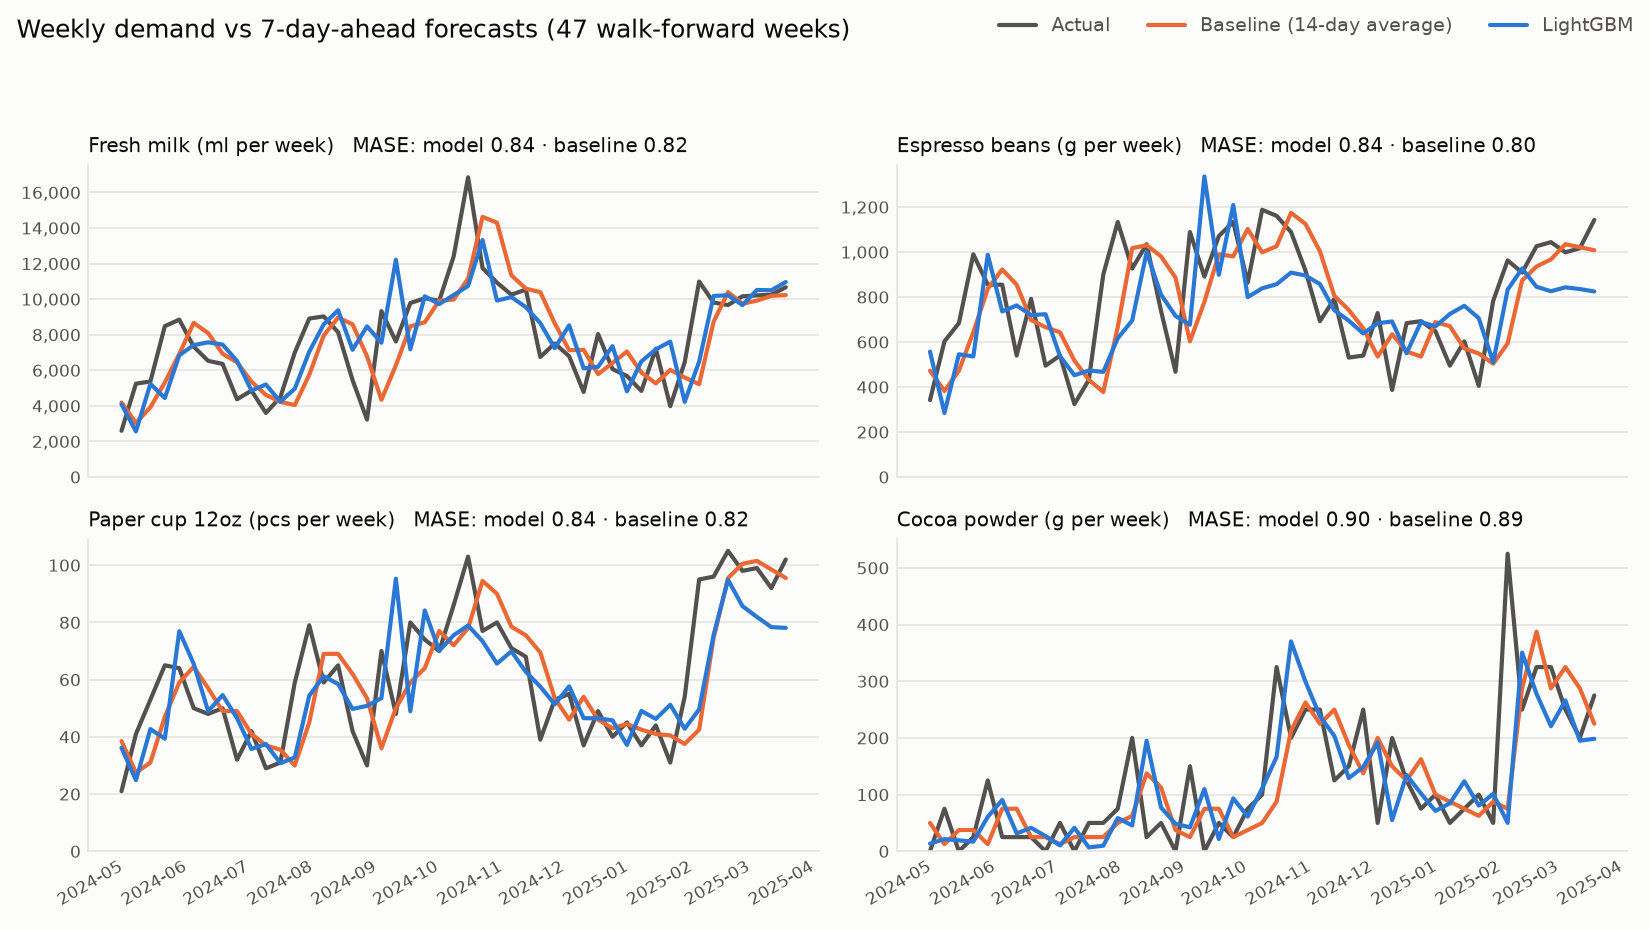

In [6]:
display(Image(filename=str(dm.OUTPUTS / "model_vs_baseline.png")))

**Reading the results.**

- **Day by day, the baseline wins.** Its MASE (0.827) is lower than the model's (0.855), and it is
  lower on every one of the eight items. Both clearly beat *same day last week* (1.000).
- **Week by week, the model is slightly better.** Its weekly WAPE is 21.4% against 23.4%, and its
  7-day total was closer in 192 item-weeks against 184 — close to a coin toss. The gain comes
  mainly from **fresh milk** (weekly WAPE 20.0% vs 22.5%), the highest-volume and only perishable item,
  and drinking chocolate.
- **Neither is noticeably biased**: over the 47 weeks both forecast slightly less than the demand
  that happened (the baseline by 2.7%, the model by 1.6%) — small next to the safety stock the
  reorder maths adds.

The honest summary: **on one year of one café's data, the ML model does not beat a well-chosen
moving average**, and the small weekly gain on milk is not large or consistent enough to justify
the extra complexity as the default.

## 6. What the model learned

Share of the model's total gain per input (final model, trained on all 388 days):

,share
feature,
std_28,18%
mean_14,17%
weekday,15%
weekday_avg_4w,14%
same_weekday_1w,11%
zero_share_28,10%
mean_7,8%
same_weekday_2w,7%
last_day,1%


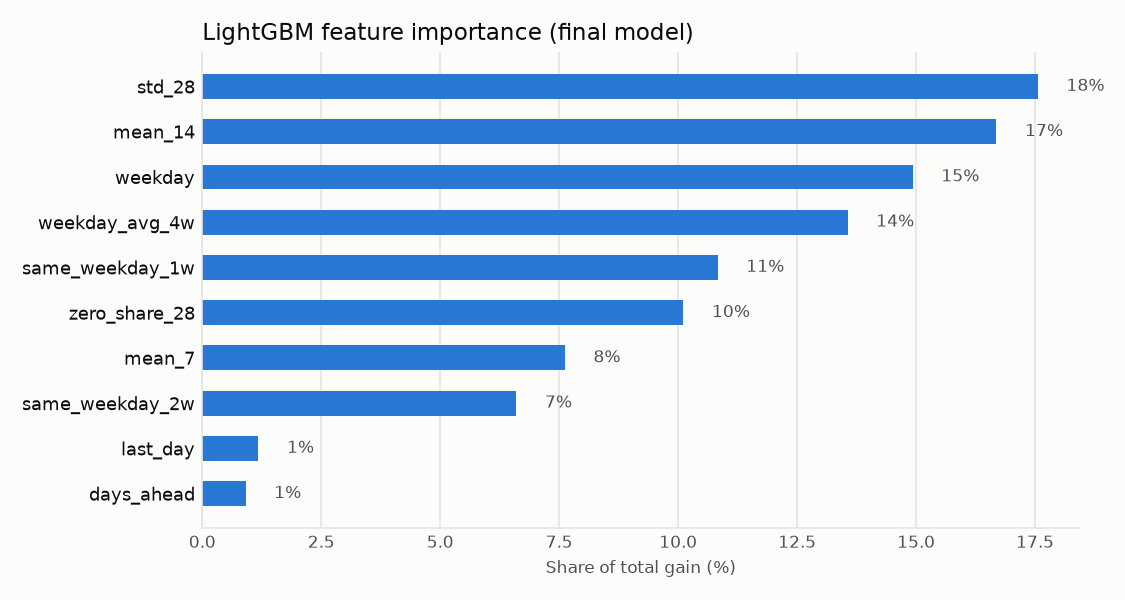

In [7]:
display(pd.DataFrame(out["feature_importance"]).set_index("feature")[["share"]].style.set_uuid("importance").format({"share": "{:.0%}"}))
display(Image(filename=str(dm.OUTPUTS / "feature_importance.png")))

The model relies on the **recent level and spread** (`mean_14`, `std_28`) and on the **weekly
rhythm** (`weekday`, `weekday_avg_4w`, `same_weekday_1w`) — the same information the moving
average and *same day last week* use, which is why it can't do much better than them. How far
ahead the day is (`days_ahead`) barely matters, as expected for a flat 7-day horizon.

## 7. Worked example

The inputs the final model sees for **fresh milk on Monday 24 March 2025** (the day after the data
ends), and what it predicts. Inputs marked "÷ level" are relative to the last 28 days' average.

In [8]:
ex = out["_extras"]["example"]
display(pd.Series(ex["inputs"], name="value").to_frame())
print(
    f"Level (average of the last 28 days): {ex['level']:,.1f} {ex['unit']}\n"
    f"Model output: {ex['model_output_scaled']:.3f} × level = {ex['prediction']:,.1f} {ex['unit']}\n"
    f"Baseline (14-day average): {ex['baseline_prediction']:,.1f} {ex['unit']}"
)

,value
days_ahead,1.000
weekday,0.000
same_weekday_1w,0.834
same_weekday_2w,1.499
weekday_avg_4w,1.592
last_day,0.644
mean_7,1.034
mean_14,1.013
std_28,0.506
zero_share_28,0.000


Level (average of the last 28 days): 1,474.6 ml
Model output: 1.289 × level = 1,901.2 ml
Baseline (14-day average): 1,494.3 ml


Mondays have been busy for milk lately (`weekday_avg_4w` ≈ 1.6× the level), so the model
predicts about 29% above the recent average, while the moving average predicts the average for
every day. Over a whole week the two largely even out — which is what the weekly results show.

## 8. Next week's forecast

What each would forecast for the week after the data ends (units per day):

In [9]:
nw = pd.DataFrame(out["_extras"]["next_week"])
weekly = nw.groupby(["item", "unit"])[["model", "baseline"]].sum()
weekly.columns = ["model, 7-day total", "baseline, 7-day total"]
weekly.style.set_uuid("next_week").format("{:,.0f}")

,,"model, 7-day total","baseline, 7-day total"
item,unit,,
Cocoa powder,g,220,237
Cup lid 12oz,pcs,83,97
Drinking chocolate,g,157,162
Espresso beans,g,931,"1,080"
Fresh milk,ml,"10,563","10,460"
Napkin,pcs,87,102
Paper cup 12oz,pcs,83,97
Paper cup 8oz,pcs,4,4


## 9. Conclusion and what CafeStock does with it

- The **14-day moving average stays the default** for the nightly reorder recommendations: it is
  as accurate or better, simpler, explainable in one sentence, and needs no ML packages.
- The **LightGBM model is kept as a challenger** (`analytics/models/lgbm-v1/model.txt`). The
  recommended nightly design (Task 10) scores both on recent weeks and uses whichever has the lower
  MASE, showing the model tag and both errors on the manager's forecast page (Task 9). If the model
  can't be loaded, the baseline runs anyway.
- What would most likely help the model, and is out of scope here: more than one year of data
  (to learn seasons), and inputs the moving average can't see — public holidays, weather,
  promotions, school terms.

## 10. Limitations

- **One café, one year.** Yearly seasonality can't be learned or separated from one-off events;
  demand roughly doubles between March and October 2024.
- **Recipe quantities are estimates.** The sales are real, but "a latte uses 220 ml of milk" is not
  measured, so ingredient demand inherits that assumption (`data/DATA_DICTIONARY.md`).
- **Sparse items** (cocoa powder, drinking chocolate, 8 oz cups) have no demand on 40–65% of days;
  daily forecasts for them are rough by any method, and MAPE is unstable for them.
- **Settings not tuned.** Tuning fairly needs a separate validation period that one year doesn't
  leave room for. A tuned model might do somewhat better; it might also just fit this year's noise.
- **Two items are duplicates** in effect (12 oz cups and lids), so they count twice in averages.
- **Forecasts beyond 7 days** repeat the first week's pattern (needed when lead time + review
  period exceeds a week).

## 11. Responsible use

- **Decision support, not automation.** Forecasts and recommendations are shown to the manager
  (manager-only page, Task 9) with their error; nothing is ordered automatically.
- **Errors cost in both directions.** Under-forecasting causes stockouts (lost sales, emergency
  top-ups); over-forecasting causes waste — mostly milk, the one perishable. Safety stock covers
  the first; the spoilage cap limits the second.
- **No personal data.** The source export has drink, time, price and cash/card only — no customers,
  names, card numbers or staff. Parts of the dataset are simulated and labelled as such.
- **Watch for drift.** New menu items, price changes or a new season can change demand; the model
  is retrained on recent data and its recent error is shown, so a drop in accuracy is visible.
- **Licence.** The Kaggle dataset's licence must be confirmed before the data is redistributed in
  the submission.

## 12. Reproduce

```bash
npm run analytics:setup      # once: installs the pinned packages (analytics/requirements.txt)
npm run analytics            # evaluation + final model → analytics/outputs/, analytics/models/lgbm-v1/
npm run analytics:notebook   # reruns this notebook and saves it
npm run analytics:test       # checks the results above are reproduced, leak-free and deterministic
```
